# Member 00

Whether the control run (member 00) should be treated differently from members 01–14. Train fold only.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from windai.data.build import load_dataset
from windai.data.splits import training_rows

pd.set_option("display.width", 200)
P = [f"p_{m:02d}" for m in range(15)]
df, curve = load_dataset("train", fit="val")
d = training_rows(df, "val")                        # train fold only, purged, observed power
X = d[P].to_numpy()
y = d["cf"].to_numpy()
zones = d["zone"].to_numpy()
ZONES = sorted(d["zone"].unique())
print(len(d), "rows,", d["issue_time"].nunique(), "issues")

104946 rows, 1094 issues


## Accuracy of the members and the ensemble mean

In [2]:
rows = {}
for z in ZONES:
    m = zones == z
    err = X[m] - y[m, None]
    r = {f"m{k:02d}": np.sqrt((err[:, k] ** 2).mean()) for k in range(15)}
    r["perturbed (median of 01-14)"] = np.median([r[f"m{k:02d}"] for k in range(1, 15)])
    r["mean 01-14"] = np.sqrt(((X[m, 1:].mean(1) - y[m]) ** 2).mean())
    r["mean all 15"] = np.sqrt(((X[m].mean(1) - y[m]) ** 2).mean())
    rows[z] = r
acc = pd.DataFrame(rows).T
acc[["m00", "perturbed (median of 01-14)", "mean 01-14", "mean all 15"]].round(4)

,m00,perturbed (median of 01-14),mean 01-14,mean all 15
ELSPOT NO1,0.1667,0.1790,0.1646,0.1643
ELSPOT NO2,0.1371,0.1660,0.1324,0.1315
ELSPOT NO3,0.1265,0.1469,0.1208,0.1203
ELSPOT NO4,0.1147,0.1236,0.1103,0.1102


In [3]:
# Rank of member 00's RMSE among all 15 members, per zone (1 = most accurate)
member_rmse = acc[[f"m{k:02d}" for k in range(15)]]
member_rmse.rank(axis=1)["m00"].astype(int).rename("rank of m00 (1 = best of 15)")

ELSPOT NO1    1
ELSPOT NO2    1
ELSPOT NO3    1
ELSPOT NO4    1
Name: rank of m00 (1 = best of 15), dtype: int64

Member 00 is the most accurate single member in every zone, with 7–17 % lower RMSE than a typical perturbed member. The ensemble mean is better still.

## Rank of member 00 within the ensemble

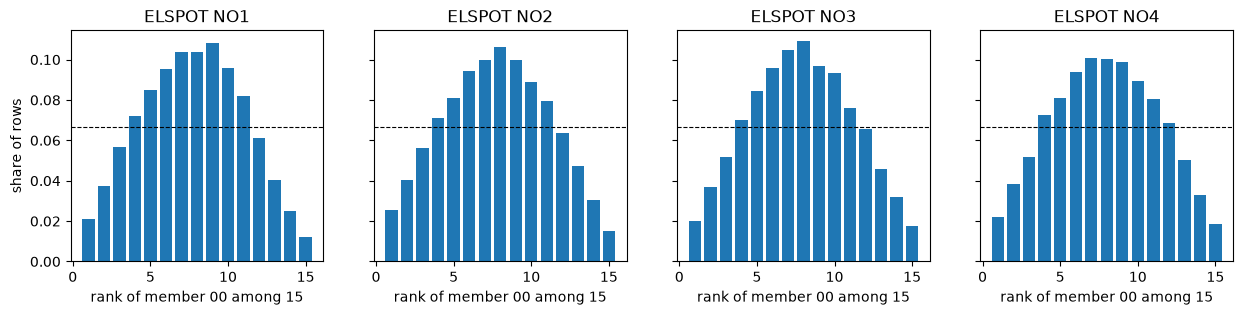

uniform: share at an edge = 2/15 = 0.133; chi2 critical value at 1 % = 29.1 (rows are serially dependent,
so the chi2 overstates significance; read it as a size measure)


,chi2 (14 df),share at an edge (rank 1 or 15)
ELSPOT NO1,5967.512,0.033
ELSPOT NO2,4839.879,0.040
ELSPOT NO3,5305.677,0.037
ELSPOT NO4,4636.644,0.040


In [4]:
rank00 = (X[:, 1:] < X[:, [0]]).sum(axis=1) + 1          # 1..15
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
chi = {}
for ax, z in zip(axes, ZONES):
    counts = np.bincount(rank00[zones == z], minlength=16)[1:]
    ax.bar(range(1, 16), counts / counts.sum())
    ax.axhline(1 / 15, color="k", lw=0.8, ls="--")
    ax.set_title(z); ax.set_xlabel("rank of member 00 among 15")
    expected = counts.sum() / 15
    chi[z] = {"chi2 (14 df)": ((counts - expected) ** 2 / expected).sum(),
              "share at an edge (rank 1 or 15)": (counts[0] + counts[-1]) / counts.sum()}
axes[0].set_ylabel("share of rows")
plt.show()
print("uniform: share at an edge = 2/15 = 0.133; chi2 critical value at 1 % = 29.1 (rows are serially dependent,")
print("so the chi2 overstates significance; read it as a size measure)")
pd.DataFrame(chi).T.round(3)

Member 00 is not exchangeable with the other members. It lies at an edge of the ensemble only 3–4 % of the time, against 13.3 % for an exchangeable member: as the unperturbed run, it sits in the middle. Rank histograms of the raw ensemble therefore use members 01–14.

## Bias of member 00

In [5]:
diff = X[:, 0] - X[:, 1:].mean(axis=1)                   # member 00 minus mean of 01-14
bias = pd.DataFrame({
    "m00 - mean(01-14)": pd.Series(diff).groupby(zones).mean(),
    "m00 - obs": pd.Series(X[:, 0] - y).groupby(zones).mean(),
    "mean(01-14) - obs": pd.Series(X[:, 1:].mean(1) - y).groupby(zones).mean(),
    "sd of m00 - mean(01-14)": pd.Series(diff).groupby(zones).std(),
})
bias.round(4)

,m00 - mean(01-14),m00 - obs,mean(01-14) - obs,sd of m00 - mean(01-14)
ELSPOT NO1,-0.0039,0.0050,0.0089,0.0479
ELSPOT NO2,-0.0054,-0.0072,-0.0018,0.0710
ELSPOT NO3,-0.0012,-0.0006,0.0007,0.0607
ELSPOT NO4,-0.0010,-0.0121,-0.0111,0.0409


Member 00 has no relevant bias relative to the perturbed members (at most 0.005 CF), and both are close to unbiased against the observations.

## A separate coefficient for member 00

Least squares on train issues before April 2022, scored on April 2022 – March 2023: (a) one coefficient on the mean of all 15 members; (b) separate coefficients on member 00 and on the mean of members 01–14.

In [6]:
split = pd.Timestamp("2022-04-01")
early = (pd.to_datetime(d["issue_date"]) + pd.Timedelta(days=2) < split).to_numpy()   # purged at the split
late = (pd.to_datetime(d["issue_date"]) >= split).to_numpy()
hour = d["target_hour_utc"].to_numpy()
designs = {"(a) mean all 15": lambda Xs: np.column_stack([np.ones(len(Xs)), Xs.mean(1)]),
           "(b) p00 + mean 01-14": lambda Xs: np.column_stack([np.ones(len(Xs)), Xs[:, 0], Xs[:, 1:].mean(1)])}
res, coefs = {}, []
for z in ZONES:
    for name, design in designs.items():
        sq, n = 0.0, 0
        for h in range(24):
            tr = early & (zones == z) & (hour == h)
            te = late & (zones == z) & (hour == h)
            beta, *_ = np.linalg.lstsq(design(X[tr]), y[tr], rcond=None)
            sq += ((design(X[te]) @ beta - y[te]) ** 2).sum(); n += te.sum()
            if name.startswith("(b)"):
                coefs.append({"zone": z, "hour": h, "b0 (m00)": beta[1], "b1 (mean 01-14)": beta[2]})
        res.setdefault(z, {})[name] = np.sqrt(sq / n)
out = pd.DataFrame(res).T
out["(b) vs (a), %"] = 100 * (out["(b) p00 + mean 01-14"] / out["(a) mean all 15"] - 1)
out.round(4)

,(a) mean all 15,(b) p00 + mean 01-14,"(b) vs (a), %"
ELSPOT NO1,0.1661,0.1654,-0.3831
ELSPOT NO2,0.1366,0.1352,-1.0426
ELSPOT NO3,0.1210,0.1218,0.6558
ELSPOT NO4,0.0975,0.0977,0.2635


In [7]:
c = pd.DataFrame(coefs).groupby("zone")[["b0 (m00)", "b1 (mean 01-14)"]].median()
c["b0 / (b0 + b1)"] = c["b0 (m00)"] / (c["b0 (m00)"] + c["b1 (mean 01-14)"])
print("median over the 24 hourly fits; under exchangeability b0 / (b0 + b1) would be about 1/15 = 0.067")
c.round(3)

median over the 24 hourly fits; under exchangeability b0 / (b0 + b1) would be about 1/15 = 0.067


,b0 (m00),b1 (mean 01-14),b0 / (b0 + b1)
zone,,,
ELSPOT NO1,0.255,0.774,0.248
ELSPOT NO2,0.374,0.647,0.366
ELSPOT NO3,0.396,0.596,0.399
ELSPOT NO4,0.209,0.787,0.210


A separate coefficient doesn't help out of sample (RMSE −1.0 % to +0.7 % by zone). Member 00 gets far more weight in the fit than one member in fifteen, but it is nearly collinear with the mean of the others, so the extra coefficient changes little. EMOS therefore uses the mean of all 15 members for the location and the spread of members 01–14 for the scale.

## Exchangeability of members 01–14

In [8]:
rows = {}
for z in ZONES:
    dev = X[zones == z, 1:] - X[zones == z, :1]           # deviation of 01-14 from member 00
    C = np.corrcoef(dev.T)
    off = C[~np.eye(14, dtype=bool)]
    rows[z] = {"min pairwise corr": off.min(), "median": np.median(off), "max": off.max()}
pd.DataFrame(rows).T.round(3)

,min pairwise corr,median,max
ELSPOT NO1,0.207,0.266,0.328
ELSPOT NO2,0.240,0.289,0.350
ELSPOT NO3,0.247,0.295,0.334
ELSPOT NO4,0.265,0.296,0.356


All pairwise correlations of the members' deviations from member 00 are positive and similar (0.21–0.36). There are no mirrored pairs, and members 01–14 behave as exchangeable.